# TODCOR on SPARTA objects

The three preceding notebooks derive and exercise the engine on plain numpy
arrays. This one runs it the way SPARTA is normally used: `Spectrum` and
`Template` objects in, radial velocities out — the double-lined counterpart of
`UNICOR_quickstart`.

| single-lined (UNICOR) | double-lined (TODCOR) |
| --- | --- |
| `CCF1d.cross_correlate(spec, template)` | `CCF2d.cross_correlate(spec, template1, template2)` |
| 1-D CCF vs velocity, peak → RV | 2-D log-likelihood over `(v1, v2)`, peak → both RVs |
| orders combined à la Zucker (2003) | orders pooled by adding sufficient statistics |
| `Observations.calc_rv_against_template` | `Observations.calc_rv_against_two_templates` |

Everything here is synthetic, so the notebook is self-contained and every
number can be checked against an injected truth.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u

import todcor as tf
from sparta import CCF2d
from sparta import Spectrum
from sparta import Template
from sparta import TimeSeries
from sparta import Observations

PAPER_STYLE = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11.0, "axes.titlesize": 11.0, "axes.labelsize": 11.0,
    "xtick.labelsize": 10.0, "ytick.labelsize": 10.0, "legend.fontsize": 8.0,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.direction": "in", "ytick.direction": "in",
    "lines.linewidth": 1.2,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.grid": False,
}
plt.rcParams.update(PAPER_STYLE)

C = tf.C_KMS                    # speed of light, km/s
rng = np.random.default_rng(20260723)

ORDERS = [(4400.0, 4600.0), (4600.0, 4800.0)]   # two "spectral orders", Angstrom
DV = 1.0                                        # log-lambda grid step, km/s
R = 60_000.0                                    # resolving power
SIGMA = 0.01                                    # per-pixel noise, in flux units

## 1. Two templates

A narrow-lined primary and a broader-lined secondary, each a small forest of
Gaussian absorption lines. Real work would use `Template.from_phoenix(teff, logg, ...)`
to pull a PHOENIX model; the engine does not care where the template came from.

Both are broadened to the instrumental resolution with the usual
`Template.broaden_instrumental`. **This matters:** TODCOR's amplitudes are the
projections of the data onto the templates, so a template whose lines are
sharper than the data's biases the amplitudes low.

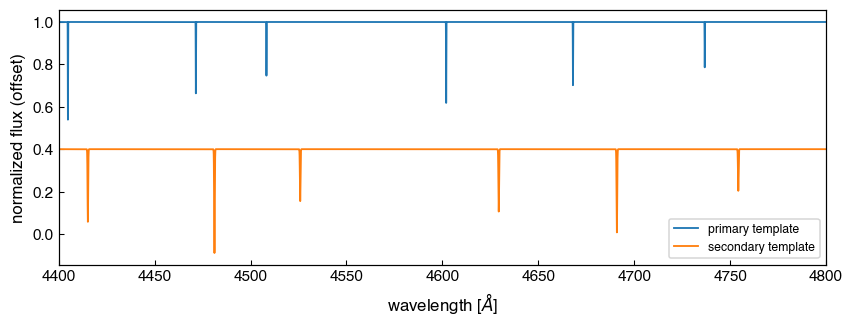

In [2]:
def line_forest(wave, centres, depths, fwhm_kms):
    """A product of Gaussian absorption lines on a normalized continuum."""
    flux = np.ones_like(wave)
    for c, d in zip(centres, depths):
        sigma = (fwhm_kms / 2.3548) * c / C
        flux *= 1.0 - d * np.exp(-0.5 * ((wave - c) / sigma) ** 2)
    return flux


wave_t = np.arange(4350.0, 4850.0, 0.02)
prim = line_forest(wave_t, [4404.8, 4471.5, 4508.3, 4602.0, 4668.1, 4736.8],
                   [0.55, 0.40, 0.30, 0.45, 0.35, 0.25], fwhm_kms=8.0)
sec = line_forest(wave_t, [4415.2, 4481.2, 4525.9, 4629.4, 4691.0, 4754.3],
                  [0.35, 0.50, 0.25, 0.30, 0.40, 0.20], fwhm_kms=25.0)

tmpl1, tmpl2 = (Template.from_arrays(wave_t, prim),
                Template.from_arrays(wave_t, sec))
tmpl1.broaden_instrumental(resolution=R)
tmpl2.broaden_instrumental(resolution=R)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(tmpl1.model.wv[0], tmpl1.model.sp[0], label='primary template')
ax.plot(tmpl2.model.wv[0], tmpl2.model.sp[0] - 0.6, label='secondary template')
ax.set_xlim(4400, 4800)
ax.set_xlabel(r'wavelength [$\AA$]')
ax.set_ylabel('normalized flux (offset)')
ax.legend(loc='lower right')
plt.show()

## 2. One synthetic observation

`composite_flux` shifts each template by physical resampling and adds them in
residual space: `1 + a1*(T1(v1) - 1) + a2*(T2(v2) - 1)`. We build the two
orders directly on a log-λ grid and say so in `Spectrum.Info`, so `CCF2d` fits
them as they are. (A spectrum on any other grid is resampled automatically —
the Fourier shift theorem only holds on a velocity-even axis.)

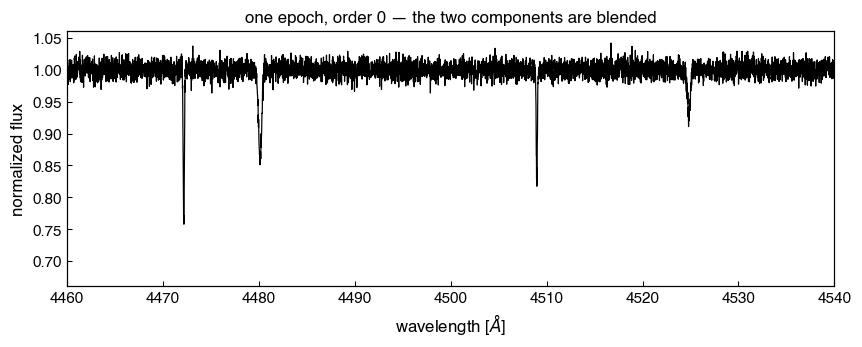

In [3]:
def make_observation(v1, v2, a1, a2, bjd, noise=SIGMA):
    """One SB2 epoch as a two-order SPARTA Spectrum on a log-lambda grid."""
    wvs, sps = [], []
    for lo, hi in ORDERS:
        grid, _ = tf.log_lambda_grid(lo, hi, DV)
        flux = tf.composite_flux(grid, [(wave_t, prim), (wave_t, sec)],
                                 [v1, v2], [a1, a2])
        flux = 1.0 + tf.broaden_gaussian_residual(flux - 1.0, DV, C / R)
        wvs.append(grid)
        sps.append(flux + rng.normal(0.0, noise, size=flux.shape))

    spec = Spectrum(wv=wvs, sp=sps, bjd=bjd, name='SB2-demo')
    spec.Info['GridType'] = 'log'
    spec.Info['GridDelta'] = DV * u.km / u.s
    return spec


V1_TRUE, V2_TRUE, A1_TRUE, A2_TRUE = 45.0, -72.0, 0.70, 0.30
spec = make_observation(V1_TRUE, V2_TRUE, A1_TRUE, A2_TRUE, bjd=0.0)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(spec.wv[0], spec.sp[0], 'k', lw=0.8)
ax.set_xlim(4460, 4540)
ax.set_xlabel(r'wavelength [$\AA$]')
ax.set_ylabel('normalized flux')
ax.set_title('one epoch, order 0 — the two components are blended')
plt.show()

## 3. The fit

Each order becomes one TODCOR *window*: templates resampled onto the observed
grid, continuum removed, apodised, then reduced to its six sufficient
statistics. The windows are summed and profiled into a single joint fit with
shared `(v1, v2, a1, a2)` — legitimate because they belong to **one epoch**.

`dvel` sets the step of the `(v1, v2)` map. Keep it coarse (cost grows as
`n1·n2`): the sub-grid quadratic refinement recovers the precision.

In [4]:
ccf = CCF2d().cross_correlate(spec, tmpl1, tmpl2,
                              vel_bound=150, dvel=2.0,
                              sigma=SIGMA, alpha=0.1, nonneg=True)
r = ccf.Corr2d

print(f"windows pooled : {ccf.n_ord}")
print(f"v1 = {r['RV1']:+7.2f} +/- {r['eRV1']:.2f} km/s   (truth {V1_TRUE:+.2f})")
print(f"v2 = {r['RV2']:+7.2f} +/- {r['eRV2']:.2f} km/s   (truth {V2_TRUE:+.2f})")
print(f"a1 = {r['a1_best']:.3f}   a2 = {r['a2_best']:.3f}"
      f"           (truth {A1_TRUE:.2f} / {A2_TRUE:.2f})")
print(f"correlation rho(v1, v2) = {r['rho12']:+.3f}")

windows pooled : 2
v1 =  +44.80 +/- 0.07 km/s   (truth +45.00)
v2 =  -72.02 +/- 0.15 km/s   (truth -72.00)
a1 = 0.711   a2 = 0.295           (truth 0.70 / 0.30)
correlation rho(v1, v2) = -0.000


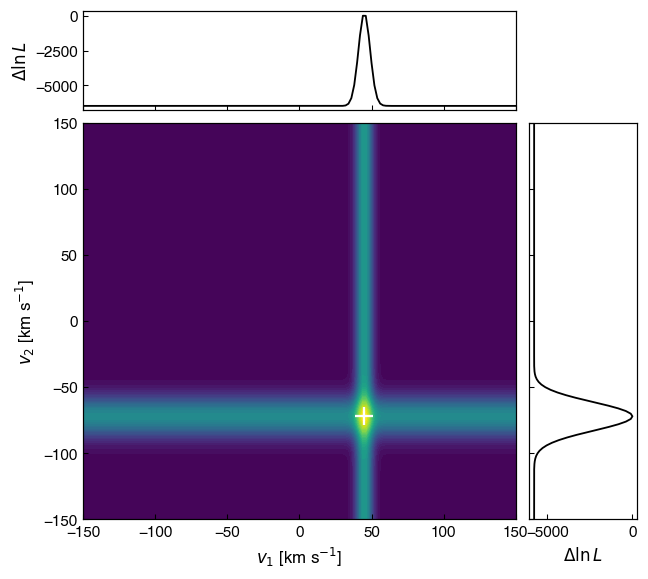

In [5]:
fig = ccf.plot(levels=40)
plt.show()

## 4. Does the best fit reproduce the data?

`best_fit_spectrum` rebuilds the composite with the *same* Fourier phase-shift
model the fit uses, so the residual is a clean check on the fit rather than on
the resampler. Away from the apodised edges it should scatter at the injected
noise level.

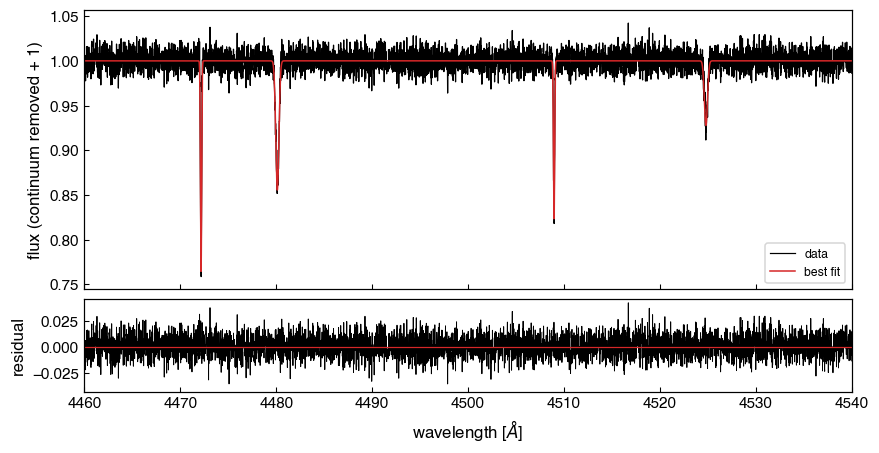

residual RMS (interior) = 0.01006   (injected sigma = 0.01)


In [6]:
wv, model, data = ccf.best_fit_spectrum(order=0)
sl = slice(len(wv) // 5, -len(wv) // 5)

fig, axs = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True,
                        gridspec_kw={'height_ratios': (3, 1), 'hspace': 0.05})
axs[0].plot(wv, data, 'k', lw=0.8, label='data')
axs[0].plot(wv, model, 'C3', lw=1.0, label='best fit')
axs[0].set_ylabel('flux (continuum removed + 1)')
axs[0].legend(loc='lower right')
axs[1].plot(wv, data - model, 'k', lw=0.6)
axs[1].axhline(0.0, color='C3', lw=0.8)
axs[1].set_xlim(4460, 4540)
axs[1].set_xlabel(r'wavelength [$\AA$]')
axs[1].set_ylabel('residual')
plt.show()

print(f"residual RMS (interior) = {np.std(model[sl] - data[sl]):.5f}"
      f"   (injected sigma = {SIGMA})")

## 5. A whole time series

`Observations.calc_rv_against_two_templates` is the SB2 counterpart of
`calc_rv_against_template`: one independent TODCOR fit per epoch. Epochs are
**never** pooled — orbital motion changes `(v1, v2)`, so a shared-velocity fit
across epochs would be meaningless.

We inject a circular double-lined orbit and read both curves back.

In [7]:
P, K1, K2, GAMMA = 3.7, 62.0, 118.0, -8.0        # days, km/s, km/s, km/s
times = np.sort(rng.uniform(0.0, 14.0, 12))
v1_inj = GAMMA + K1 * np.sin(2 * np.pi * times / P)
v2_inj = GAMMA - K2 * np.sin(2 * np.pi * times / P)

specs = [make_observation(a, b, A1_TRUE, A2_TRUE, t)
         for a, b, t in zip(v1_inj, v2_inj, times)]

obs = Observations(time_series=TimeSeries(size=len(specs),
                                          times=list(times), vals=specs))
obs.calc_rv_against_two_templates(tmpl1, tmpl2, vel_bound=200, dvel=2.0,
                                  sigma=SIGMA)

  0%|          | 0/12 [00:00<?, ?it/s]

  8%|▊         | 1/12 [00:00<00:01,  7.05it/s]

 17%|█▋        | 2/12 [00:00<00:01,  7.84it/s]

 25%|██▌       | 3/12 [00:00<00:01,  8.37it/s]

 33%|███▎      | 4/12 [00:00<00:00,  8.61it/s]

...

 75%|███████▌  | 9/12 [00:01<00:00,  9.01it/s]

 83%|████████▎ | 10/12 [00:01<00:00,  9.10it/s]

 92%|█████████▏| 11/12 [00:01<00:00,  9.08it/s]

100%|██████████| 12/12 [00:01<00:00,  8.98it/s]

100%|██████████| 12/12 [00:01<00:00,  8.80it/s]

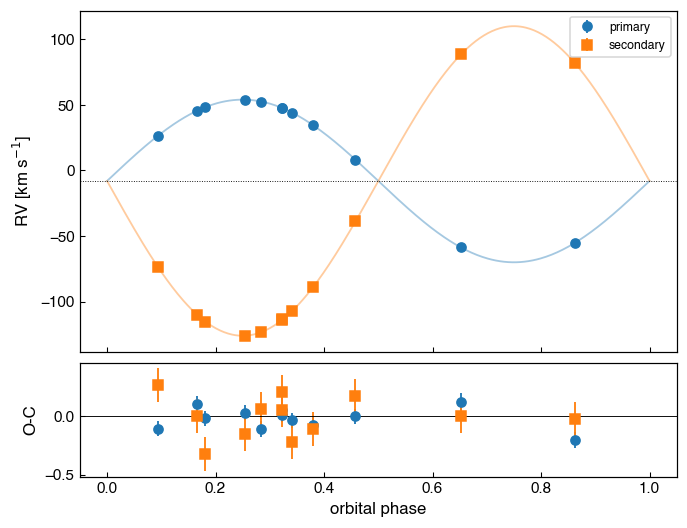

v1: rms(O-C) = 0.090 km/s, median CRLB = 0.066 km/s
v2: rms(O-C) = 0.168 km/s, median CRLB = 0.146 km/s
amplitudes: a1 = 0.708 +/- 0.023,  a2 = 0.299 +/- 0.003


In [8]:
phase = (times % P) / P
grid = np.linspace(0, 1, 400)

fig, axs = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True,
                        gridspec_kw={'height_ratios': (3, 1), 'hspace': 0.05})
axs[0].plot(grid, GAMMA + K1 * np.sin(2 * np.pi * grid), 'C0', alpha=0.4)
axs[0].plot(grid, GAMMA - K2 * np.sin(2 * np.pi * grid), 'C1', alpha=0.4)
axs[0].errorbar(phase, obs.vels1, obs.evels1, fmt='o', color='C0',
                label='primary')
axs[0].errorbar(phase, obs.vels2, obs.evels2, fmt='s', color='C1',
                label='secondary')
axs[0].axhline(GAMMA, color='k', lw=0.6, ls=':')
axs[0].set_ylabel(r'RV [km s$^{-1}$]')
axs[0].legend(loc='upper right')

axs[1].errorbar(phase, obs.vels1 - v1_inj, obs.evels1, fmt='o', color='C0')
axs[1].errorbar(phase, obs.vels2 - v2_inj, obs.evels2, fmt='s', color='C1')
axs[1].axhline(0.0, color='k', lw=0.6)
axs[1].set_xlabel('orbital phase')
axs[1].set_ylabel('O-C')
plt.show()

print(f"v1: rms(O-C) = {np.std(obs.vels1 - v1_inj):.3f} km/s,"
      f" median CRLB = {np.median(obs.evels1):.3f} km/s")
print(f"v2: rms(O-C) = {np.std(obs.vels2 - v2_inj):.3f} km/s,"
      f" median CRLB = {np.median(obs.evels2):.3f} km/s")
print(f"amplitudes: a1 = {np.mean(obs.amps1):.3f} +/- {np.std(obs.amps1):.3f},"
      f"  a2 = {np.mean(obs.amps2):.3f} +/- {np.std(obs.amps2):.3f}")

## 6. Reading the numbers honestly

The scatter of the primary sits above its Cramér–Rao bound, and that is
expected rather than a bug — the CRLB assumes white, homoscedastic noise on
the analysis grid, and two preprocessing steps break that assumption:

- the **Tukey taper** makes the noise heteroscedastic (`sigma_n = w_n·sigma`);
- **resampling** the templates onto the observed grid *correlates* neighbouring
  pixels' noise.

Only the overall *scale* is recoverable: if the reduced χ² is not ≈ 1, multiply
the returned σ by `sqrt(chi2_red)`. See [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md) §8–9.

Two more things worth carrying into real data:

- **Broaden the templates to match the data** (rotation *and* instrument), or
  the amplitudes come out low — the fit is a projection, and a width mismatch
  costs you projection.
- **Watch the degeneracy.** When the two components are close in velocity the
  template–template term `A12²` approaches `S11·S22`, the normal matrix becomes
  ill-conditioned, and the CRLB stops being meaningful (it returns `nan` off a
  positive-definite Hessian). The `rho12` correlation is the early warning.

Further reading: [`todcor_method.md`](../../packages/todcor/docs/todcor_method.md) for the full derivation, and Zucker &
Mazeh (1994, ApJ 420, 806) for the original TODCOR.